## Generate Data from Logical Rules

In [7]:
import math
import pickle
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from ANDRE_Net2 import ANDRE
from collections import Counter
from utils import check_binary_dataset, create_V_matrix
from utils import plot_andre_weights
from utils import interpret_neuron_weights_entropy, interpret_neuron_weights
from utils import compute_acc_ratio_all_rules_attention
from utils import extract_rules
from utils import parse_rule_and_generate_data
import numpy as np
from datetime import datetime

today_date = datetime.now().strftime("%Y-%m-%d")
today_hour = datetime.now().strftime("%H-%M-%S")

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# device = torch.device("cpu")
print(f"Using device: {device}")

synthetic_data = False
structured_data = True 
visualize_weights = False
verbose = True
save_model = False
dataset_type = "binary"
# dataset_type = "continuous"
seed = 42

if synthetic_data:

    Num_rules = 4
    num_samples = 200
    num_epochs = 500
    num_restarts = 3
    batch_size = 128

    sim_weight, ent_weight, rr_weight, conn_weight, digit_weight = 0.03, 0.1, 1, 5, 0.01

    if not structured_data:
        input_dim = 6
        num_samples = 200 * input_dim
        body_predicates = [f"b{i+1}" for i in range(input_dim)]
        head_predicate = "h"
        variable_matrix, variables = None, None
        body_predicates = None
        head_predicate = None
    else:
        body_predicates = ["father(X1, X2)", "father(X2, X3)", "father(X1, X3)", "mother(X1, X2)", "mother(X2, X3)", "mother(X1, X3)"]
        head_predicate = "grandparent(X1, X3)"
        variable_matrix, variables = create_V_matrix(body_predicates)
        head_vars = [0, 2]
        connected_vars = [1]
        input_dim = len(body_predicates)
        body_predicates = body_predicates
        head_predicate = head_predicate
    
    # Generate Random Dataset
    torch.manual_seed(seed)
    if dataset_type == "binary":
        X_train = (torch.rand(num_samples, input_dim) > 0.5).float()
        acc_threshold = 0.98
    else:
        X_train = torch.rand(num_samples, input_dim)
        acc_threshold = 0.98

    if check_binary_dataset(X_train):
        # print("X_train is a binary dataset. We are perturbing the data for better training.")
        # perturb data by adding small noise to zero and reducing one to less than one
        X_train = X_train - 0.1 * torch.rand_like(X_train) * (X_train - 0.5).sign()
        # clip to [0, 1]
        X_train = torch.clamp(X_train, 0.0, 1.0)
        
    # y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 9]) > 0.5)) | ((X_train[:, 1] > 0.5) & (X_train[:, 8] > 0.5)) | 
    #            ((X_train[:, 2] > 0.5) & (X_train[:, 7] > 0.5))).float()

    # Fix: ensure each arithmetic expression is compared before using bitwise AND/OR.
    # Without proper parentheses a float tensor can be used with '&' which raises the runtime error.
    # y_train = (
    #     (
    #         (X_train[:, 0] > 0.5) & ((1 - X_train[:, 5]) > 0.5) & (X_train[:, 9] > 0.5)
    #     )
    #     |
    #     (
    #         ((1 - X_train[:, 2]) > 0.5) & ((1 - X_train[:, 4]) > 0.5) & (X_train[:, 8] > 0.5)
    #     )
    # ).float()

    y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | 
            ((X_train[:, 0] > 0.5) & (X_train[:, 4] > 0.5)) | 
            ((X_train[:, 3] > 0.5) & (X_train[:, 4] > 0.5)) | 
            ((X_train[:, 3] > 0.5) & (X_train[:, 1] > 0.5))).float()
    # Move to device
    # X_train = X_train.to(device)
    # y_train = y_train.to(device)

else:
    Num_rules = 4
    num_samples = 128
    num_epochs = 10
    num_restarts = 1
    batch_size = 128
    sim_weight, ent_weight, rr_weight, conn_weight, digit_weight = 0.03, 0.1, 0.2, 1, 0.03

    # Load your dataset here
    file_path = 'test_dir/'

    # read the x_train.dt and y_train.dt files
    with open(file_path + 'x_train.dt', 'rb') as xf:
        x_train = pickle.load(xf)
        xf.close()
    with open(file_path + 'y_train.dt', 'rb') as yf:
        y_train = pickle.load(yf)
        yf.close()

    print("👉 The x_train data is:")
    print(len(x_train[0]))
    print("👉 The y_train data is:")
    print(len(y_train))

    x_train_np = np.concatenate(x_train, axis=1)
    X_train = torch.tensor(x_train_np[:, :-1], dtype=torch.float32)
    y_train = torch.tensor(x_train_np[:, -1], dtype=torch.float32)
    # Move to device
    X_train = X_train.to(device)
    y_train = y_train.to(device)

    if check_binary_dataset(X_train):
        dataset_type = "binary"
        print("X_train is a binary dataset. We are perturbing the data for a better training.")
        # perturb data by adding small noise to zero and reducing one to less than one
        X_train = X_train - 0.1 * torch.rand_like(X_train) * (X_train - 0.5).sign()
        # clip to [0, 1]
        X_train = torch.clamp(X_train, 0.0, 1.0)

    # Load the predicate list
    with open(file_path + 'predicate.list', 'rb') as f:
        predicate_list = pickle.load(f)
        f.close()

    # Load relation variable permutations
    with open(file_path + 'relation_variable.dt', 'rb') as f:
        relation_variable_permutations = pickle.load(f)
        f.close()

    # Load relation names
    with open(file_path + 'all_relation_dic.dt', 'rb') as f:
        all_relations = pickle.load(f)
        f.close()

    print("Predicates:", len(predicate_list))
    print("Relations:", len(all_relations))
    print("Variable permutations:", len(relation_variable_permutations))

    def get_predicate_name(index, predicate_list, relation_variable_permutations, all_relations):
        """
        Convert a feature index in X_train to its symbolic predicate name.
        """
        # Get variable mapping (e.g., (0, 1) for X, Y)
        var_tuple = predicate_list[index]
        
        # Variable name mapping
        var_names = {0: 'X1', 1: 'X2', 2: 'X3', 3: 'X4'}
        
        # Find which relation this belongs to
        cumulative_index = 0
        for relation_name, permutations in relation_variable_permutations.items():
            if cumulative_index <= index < cumulative_index + len(permutations):
                # Found the relation
                local_index = index - cumulative_index
                var_pair = permutations[local_index]
                
                # Build symbolic predicate
                symbolic = f"{relation_name}({var_names[var_pair[0]]}, {var_names[var_pair[1]]})"
                return symbolic
            
            cumulative_index += len(permutations)
        
        return "Unknown"

    # Example: Map X_train column 0
    body_predicates = []
    for idx in range(len(predicate_list)):
        predicate_name = get_predicate_name(idx, predicate_list, 
                                            relation_variable_permutations, 
                                            all_relations)
        # print(f"X_train[:, {idx}] = {predicate_name}")
        body_predicates.append(predicate_name)

    print("head predicate:", body_predicates[252])
    head_predicate = "blockpositionindex(X1, X2)" #body_predicates[252]  # Example head predicate
    for idx in range(len(predicate_list)):
        if body_predicates[idx] == head_predicate:
            headpred_idx = idx
            print(f"Found head predicate at index {idx} in body predicates.")
            break

    # remove the head predicate from body predicates
    body_predicates.remove(head_predicate)
    print("Number of body predicates:", len(body_predicates))

    # remove the corresponding column from X_train
    X_train = torch.cat((X_train[:, :headpred_idx], X_train[:, headpred_idx+1:]), dim=1)

    # check if the length of body_predicates matches the number of columns in X_train
    assert len(body_predicates) == X_train.shape[1], "Mismatch between body predicates and X_train columns."
    
    variable_matrix, variables = create_V_matrix(body_predicates)
    head_vars = [0, 1] # X1, X2
    connected_vars = [2, 3] # X3, X4

    input_dim = X_train.shape[1]
    num_samples = X_train.shape[0]

    acc_threshold = 0.95

Using device: cuda
👉 The x_train data is:
38416
👉 The y_train data is:
38416
X_train is a binary dataset. We are perturbing the data for a better training.
Predicates: 660
Relations: 55
Variable permutations: 55
head predicate: blockpositionindex(X1, X2)
Found head predicate at index 252 in body predicates.
Number of body predicates: 659
👉 The x_train data is:
38416
👉 The y_train data is:
38416
X_train is a binary dataset. We are perturbing the data for a better training.
Predicates: 660
Relations: 55
Variable permutations: 55
head predicate: blockpositionindex(X1, X2)
Found head predicate at index 252 in body predicates.
Number of body predicates: 659


In [8]:
# Remove predicates containing 'X4' and corresponding columns in X_train
# This cell updates: body_predicates, predicate_list (if present), variable_matrix (if present), X_train, and input_dim.

# Find indices to keep (predicates without 'X4')
indices_keep = [i for i, p in enumerate(body_predicates) if "X4" not in p]
indices_remove = [i for i, p in enumerate(body_predicates) if "X4" in p]

if not indices_remove:
    print("No predicates containing 'X4' were found. No changes made.")
else:
    # Update body_predicates
    body_predicates = [body_predicates[i] for i in indices_keep]

    variable_matrix, variables = create_V_matrix(body_predicates)

    head_vars = [0, 1]

    connected_vars = [2]

    # Update X_train (keep columns corresponding to indices_keep)
    X_train = X_train[:, indices_keep].clone()

    # Update input_dim
    input_dim = X_train.shape[1]

    # Summary
    print(f"Removed {len(indices_remove)} predicates containing 'X4'.")
    print(f"Old input_dim -> New input_dim: {input_dim}")

Removed 330 predicates containing 'X4'.
Old input_dim -> New input_dim: 329


In [9]:
# Create a validation split (20%) and remove those examples from X_train / y_train
n = X_train.size(0)
val_size = max(1, int(0.2 * n))

# reproducible permutation if seed exists
try:
    g = torch.Generator()
    g.manual_seed(seed)
    perm = torch.randperm(n, generator=g)
except NameError:
    perm = torch.randperm(n)

val_idx = perm[:val_size]
train_idx = perm[val_size:]

# create validation tensors and update training tensors (clone to avoid accidental views)
X_val = X_train[val_idx].clone()
y_val = y_train[val_idx].clone()

X_train = X_train[train_idx].clone()
y_train = y_train[train_idx].clone()

# update num_samples to reflect new training set size
num_samples = X_train.size(0)

print(f"Train set: {X_train.shape}, Validation set: {X_val.shape}, num_samples (train) = {num_samples}")

# Move to device

X_train = X_train.to(device)

y_train = y_train.to(device)

X_val = X_val.to(device)
y_val = y_val.to(device)

Train set: torch.Size([30733, 329]), Validation set: torch.Size([7683, 329]), num_samples (train) = 30733


In [10]:
def schedule_rr_conn_digit_weight(epoch, total_epochs, initial_rr_weight, max_rr_weight, initial_conn_weight, max_conn_weight, initial_digit_weight, max_digit_weight):
    # Linearly increase rr_weight and conn_weight from 0 to their initial values over the epochs
    rr_weight = initial_rr_weight + (epoch / total_epochs)**2 * max_rr_weight
    conn_weight = initial_conn_weight + (epoch / total_epochs)**2 * max_conn_weight
    digit_weight = initial_digit_weight + (epoch / total_epochs)**2 * max_digit_weight

    rr_weight = min(rr_weight, max_rr_weight)
    conn_weight = min(conn_weight, max_conn_weight)
    digit_weight = min(digit_weight, max_digit_weight)
    
    return rr_weight, conn_weight, digit_weight

#### Learning Without Curriculum Learning


=== Training ANDRE with 1 rules, Restart 1/1 ===
Extracted Rule: blockpositionindex(X1, X2) :- blockpositionindex(X2, X1) and not(unoffialacts(X2, X1)).

Final Rule:
blockpositionindex(X1, X2) :- blockpositionindex(X2, X1) and not(unoffialacts(X2, X1)).
Num Rules: 1, Restart 1/1, Train Metric: 0.9418, Evaluation Metric: 0.9385.
**** New Best Model ****

=== Training ANDRE with 2 rules, Restart 1/1 ===
Extracted Rule: blockpositionindex(X1, X2) :- blockpositionindex(X2, X1) and not(unoffialacts(X2, X1)).

Final Rule:
blockpositionindex(X1, X2) :- blockpositionindex(X2, X1) and not(unoffialacts(X2, X1)).
Num Rules: 1, Restart 1/1, Train Metric: 0.9418, Evaluation Metric: 0.9385.
**** New Best Model ****

=== Training ANDRE with 2 rules, Restart 1/1 ===
Extracted Rule: blockpositionindex(X1, X2) :- weightedunvote(X1, X2) and commonbloc0(X1, X2) and timesinceally(X2, X1).
Extracted Rule: blockpositionindex(X1, X2) :- blockpositionindex(X2, X1) and not(expeldiplomats(X2, X1)).

Final Rule:

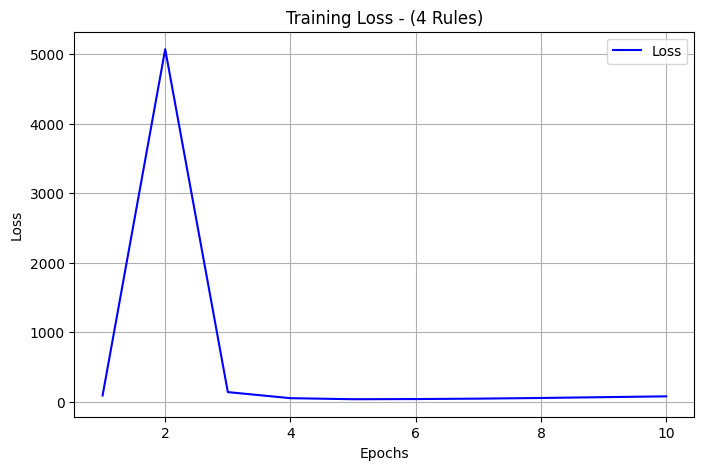

Extracted Rule: blockpositionindex(X1, X2) :- not(relbooktranslations(X1, X2)) and blockpositionindex(X2, X1) and conferences(X1, X2).
Extracted Rule: blockpositionindex(X1, X2) :- relbooktranslations(X2, X1) and blockpositionindex(X2, X1) and not(officialvisits(X2, X1)) and conferences(X1, X2).
Extracted Rule: blockpositionindex(X1, X2) :- blockpositionindex(X2, X1) and not(expeldiplomats(X2, X1)).
Extracted Rule: blockpositionindex(X1, X2) :- weightedunvote(X1, X2) and not(commonbloc2(X2, X1)) and not(exports3(X2, X1)) and conferences(X1, X2) and not(exportbooks(X2, X1)) and not(tourism3(X2, X1)).

Final Rule:
blockpositionindex(X1, X2) :- not(relbooktranslations(X1, X2)) and blockpositionindex(X2, X1) and conferences(X1, X2) OR relbooktranslations(X2, X1) and blockpositionindex(X2, X1) and not(officialvisits(X2, X1)) and conferences(X1, X2) OR blockpositionindex(X2, X1) and not(expeldiplomats(X2, X1)) OR weightedunvote(X1, X2) and not(commonbloc2(X2, X1)) and not(exports3(X2, X1)) a

In [11]:
# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_eval_metric = -float('inf')
best_train_metric = -float('inf')
best_overall_metric = -float('inf')
best_losses = []

# Move data to device
# X_train = X_train.to(device)
# y_train = y_train.to(device)


for num_rules in range(Num_rules):
# for num_rules in [0]:

    for restart in range(num_restarts):
        print(f"\n=== Training ANDRE with {num_rules + 1} rules, Restart {restart + 1}/{num_restarts} ===")
        model = ANDRE(num_rules + 1, pot_body_pred_dim=input_dim, variable_matrix=variable_matrix if structured_data else None, lr=0.01, weight_decay=0)
        model = model.to(device)

        losses_andre = []

        for epoch in range(num_epochs):
            model.train()

            # Shuffle dataset
            perm = torch.randperm(num_samples)
            X_train_shuffled = X_train[perm]
            y_train_shuffled = y_train[perm]

            epoch_loss = 0.0

            # Mini-batch training loop
            for i in range(0, num_samples, batch_size):
                xb = X_train_shuffled[i:i + batch_size]
                yb = y_train_shuffled[i:i + batch_size]

                model.optimizer.zero_grad()
                outputs, model_weights, weight_entropies, Ms = model(xb)

                # Binary Cross-Entropy Loss
                bce_loss = model.criterion(outputs, yb)

                # Similarity Penalty
                sim_loss = 0.0
                num_sim_pairs = 0
                for i in range(num_rules + 1):
                    wi = model_weights[i].view(input_dim, -1)
                    for j in range(i + 1, num_rules + 1):
                        wj = model_weights[j].view(input_dim, -1)
                        sim_loss += nn.CosineSimilarity(dim=1)(wi, wj).mean()
                        num_sim_pairs += 1
                sim_loss = sim_loss / num_sim_pairs if num_sim_pairs > 0 else 0

                if structured_data:
                    # print("M_matrices:", Ms)

                    # Build tensors from M entries (handle lists or tensors)
                    M_head_list = [torch.as_tensor(Ms[i][head_vars], device=xb.device, dtype=xb.dtype) for i in range(num_rules + 1)]
                    M_head = torch.stack(M_head_list)

                    # Range Restriction Loss with asymmetric penalty
                    eta = 0.5  # Small penalty for values above 1
                    mask_below = (M_head < 1.0).float()
                    mask_above = (M_head >= 1.0).float()
                    rr_loss_1 = mask_below * (M_head - 1.0)**2 + mask_above * eta * (M_head - 1.0)
                    rr_loss = rr_loss_1
                    rr_loss = rr_loss.sum() / len(head_vars) / (num_rules + 1)
                    # rr_loss = rr_loss.sum() / xb.size(0) / len(head_vars) / (num_rules + 1) / input_dim

                    # Connectivity Loss
                    M_connected_list = [torch.as_tensor(Ms[i][connected_vars], device=xb.device, dtype=xb.dtype) for i in range(num_rules + 1)]
                    M_connected = torch.stack(M_connected_list)  # tensor form

                    # Connectivity Loss with conditional masking
                    mask_below_2 = (M_connected < 2.0).float()
                    mask_above_2 = (M_connected >= 2.0).float()
                    
                    # Smoothness / connectivity term computed elementwise and averaged
                    conn_loss_1 = torch.stack([torch.exp(-0.5 * ((M_conn - 1.0) / 0.2)**2) / (0.2 * math.sqrt(2 * math.pi)) for M_conn in M_connected]).sum()
                    conn_loss_1 = 0.5 * conn_loss_1
                    
                    # MSE against constant 2
                    conn_loss_2 = (M_connected - 2.0)**2
                    
                    # Apply masking: use conn_loss_1 if below 2, conn_loss_2 if above or equal to 2
                    conn_loss = mask_below_2 * conn_loss_1 + mask_above_2 * conn_loss_2
                    conn_loss = conn_loss.sum() / len(connected_vars) / (num_rules + 1)

                    # Digitization Loss - encourage M elements to be integers
                    M_all_list = [torch.as_tensor(Ms[i], device=xb.device, dtype=xb.dtype) for i in range(num_rules + 1)]
                    M_all = torch.stack(M_all_list)  # [num_rules+1, num_variables]
                    digit_loss = 0.5 * (1 - torch.sin(2 * math.pi * M_all + math.pi / 2)).sum()
                    digit_loss = digit_loss / M_all.numel()

                    # Entropy Loss
                    entropy_term = torch.stack(weight_entropies).sum()
                    entropy_term = entropy_term / (num_rules + 1) /  input_dim

                    rr_weight_, conn_weight_, digit_weight_ = schedule_rr_conn_digit_weight(epoch=epoch, total_epochs=num_epochs, 
                                                                       initial_rr_weight=0, max_rr_weight=rr_weight, 
                                                                       initial_conn_weight=0, max_conn_weight=conn_weight,
                                                                       initial_digit_weight=0, max_digit_weight=digit_weight)

                    # Total Loss
                    total_loss = bce_loss + ent_weight * entropy_term + rr_weight_ * rr_loss + conn_weight_ * conn_loss + digit_weight_ * digit_loss

                    # if epoch % 10 == 0:
                    #     print("bce_loss", bce_loss.item(), "entropy_term:", ent_weight * entropy_term.item(), "rr_loss:", rr_weight_ * rr_loss.item(), 
                    #       "conn_loss:", conn_weight_ * conn_loss.item(), "digitization penalty:", digit_weight_ * digit_loss.item(), "Similarity penalty:", sim_weight * sim_loss)
                        # print("bce_loss", bce_loss.item(), "entropy_term:", entropy_term.item(), "rr_loss:", rr_loss.item(), 
                        #   "conn_loss:", conn_loss.item(), "penalty:", sim_loss)

                else: 
                    entropy_term = torch.stack(weight_entropies).sum()
                    entropy_term = entropy_term / (num_rules + 1) /  input_dim
                    total_loss = bce_loss + ent_weight * entropy_term
                    # print("bce_loss", bce_loss.item(), "entropy_term:", ent_weight * entropy_term.item())

                total_loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                model.optimizer.step()

                epoch_loss += total_loss.item()

            model.scheduler.step()
            losses_andre.append(epoch_loss)
            # print(f"Num Rules: {num_rules + 1}, Restart {restart+1}/{num_restarts}, Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}.")
            # Evaluate model per epoch

            # metrics = model.evaluate(X_val, y_val)
            # accuracy = metrics['accuracy']
            # precision = metrics['precision']
            # recall = metrics['recall']
            # f1_score = metrics['f1_score']
            # print(f"Rule: {num_rules + 1}, Epoch: {epoch+1}, Evaluation Metrics - Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1-Score: {f1_score:.4f}") 

        if verbose:

            Weights_andre = []
            for rule_weights in model_weights:
                rule_weights = rule_weights.detach().cpu().numpy()
                body_predicate_weights = rule_weights.reshape(-1, 3)
                Weights_andre.append(body_predicate_weights.tolist())

            # Rule interpretation
            final_rule = extract_rules(Weights_andre=Weights_andre, X_train=X_train, 
                                    dataset_type=dataset_type, body_predicates=body_predicates,
                                    head_predicate=head_predicate)
            print("\n======================================")
            print("Final Rule:")
            print(final_rule)
            print("======================================")

        training_metrics = model.evaluate(X_train, y_train)
        # accuracy = training_metrics['accuracy']
        # precision = training_metrics['precision']
        # recall = training_metrics['recall']
        # f1_score = training_metrics['f1_score']
        # print(f"Training Metrics - Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1-Score: {f1_score:.4f}") 

        # Evaluate model
        evaluation_metrics = model.evaluate(X_val, y_val)
        # accuracy = evaluation_metrics['accuracy']
        # precision = evaluation_metrics['precision']
        # recall = evaluation_metrics['recall']
        # f1_score = evaluation_metrics['f1_score']
        # print(f"Evaluation Metrics - Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1-Score: {f1_score:.4f}") 

        # hard_metric = 0.25 * (accuracy + precision + recall + f1_score)

        eval_metric = 0.5 * (evaluation_metrics['accuracy'] + evaluation_metrics['recall'])
        train_metric = 0.5 * (training_metrics['accuracy'] + training_metrics['recall'])

        overall_metric = 0.5 * (train_metric + eval_metric)

        print(f"Num Rules: {num_rules + 1}, Restart {restart+1}/{num_restarts}, Train Metric: {train_metric:.4f}, Evaluation Metric: {eval_metric:.4f}.")
        if min(losses_andre) < best_loss:
            print(f"**** New Best Model ****")
            best_eval_metric = eval_metric
            best_train_metric = train_metric
            best_overall_metric = overall_metric
            best_state_dict = deepcopy(model.state_dict())
            best_losses = losses_andre
            best_num_rules = num_rules + 1
            best_loss = min(losses_andre)

            if train_metric > acc_threshold and eval_metric > acc_threshold:
                print(f"The accuracy threshold of {acc_threshold} has been reached. Stopping further restarts.")
                break

# Load the best model
best_model = ANDRE(best_num_rules, pot_body_pred_dim=input_dim, variable_matrix=variable_matrix if structured_data else None, lr=0.005, weight_decay=1e-4)
best_model.load_state_dict(best_state_dict)
best_model = best_model.to(device)

# Evaluate best model
print("\n=== Best Model Training Evaluation ===")
best_model.print_evaluation(X_train, y_train)

print("\n=== Best Model Evaluation on Validation Set ===")
best_model.print_evaluation(X_val, y_val)

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss - ({best_num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

_, andre_weights, _, _ = best_model(X_val)

Weights_andre = []
for rule_weights in andre_weights:
    rule_weights = rule_weights.detach().cpu().numpy()
    body_predicate_weights = rule_weights.reshape(-1, 3)
    Weights_andre.append(body_predicate_weights.tolist())

if visualize_weights:
    plot_andre_weights(Weights_andre, input_dim=input_dim, predicates=body_predicates, structured_data=structured_data)

# Rule interpretation
final_rule = extract_rules(Weights_andre=Weights_andre, X_train=X_train, 
                           dataset_type=dataset_type, body_predicates=body_predicates,
                           head_predicate=head_predicate)
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")

# Save the best model
if save_model:
    best_model.save_model(save_dir=f"saved_models/andre_best_model_{today_date}", model_name=f"ANDRE_best_model_{today_hour}")

### Sort Rules by Accuracy

In [60]:
# Extract and evaluate individual rules, then sort by accuracy

def evaluate_single_rule(rule_weights, X_data, y_data, variable_matrix=None):
    """
    Create a single-rule ANDRE model and evaluate its accuracy.
    
    Args:
        rule_weights: List of weights for all neurons in the rule
        X_data: Input features
        y_data: True labels
        input_dim: Number of input dimensions
        variable_matrix: Variable matrix for structured data
        
    Returns:
        Dictionary with accuracy and other metrics
    """

    # Find x_data columns as input_dim
    input_dim = X_data.shape[1]

    # Create single-rule ANDRE model
    single_rule_model = ANDRE(num_rules=1, pot_body_pred_dim=input_dim, 
                              variable_matrix=variable_matrix, lr=0.005, weight_decay=1e-4)
    single_rule_model = single_rule_model.to(device)
    
    # Load the weights for this single rule
    # In ANDRE_Net2, the structure is: rules[0] is a RuleBlock, which contains activation (ProbSumActivation)
    # The raw_weights are in the activation layer
    with torch.no_grad():
        # Stack all neuron weights into a single tensor [input_dim, 3]
        weights_array = torch.tensor(rule_weights, dtype=torch.float32)  # [input_dim, 3]
        # Use log to approximate inverse softmax
        single_rule_model.rules[0].activation.raw_weights.data = torch.log(weights_array + 1e-10)
    
    # Evaluate the single rule
    single_rule_model.eval()
    metrics = single_rule_model.evaluate(X_data, y_data)
    
    return metrics


# Evaluate each rule individually
print("\n" + "="*70)
print("INDIVIDUAL RULE EVALUATION")
print("="*70)

rule_evaluations = []

for rule_idx, rule_weights in enumerate(Weights_andre):
    print(f"\nEvaluating Rule {rule_idx + 1}...")
    
    # Evaluate this rule
    metrics = evaluate_single_rule(
        rule_weights, 
        X_train, 
        y_train, 
        variable_matrix if structured_data else None
    )
    
    # Extract the rule text
    if dataset_type == "binary":
        preds = interpret_neuron_weights(body_preds=body_predicates, Weights=rule_weights)
    else:
        # For probabilistic, use a representative sample
        sample_pred_values = X_train[0].numpy()
        preds = interpret_neuron_weights_entropy(sample_pred_values, rule_weights)
    
    refined_preds = [pred for pred in preds if pred != '1' and pred != '?']
    rule_text = " and ".join(refined_preds) if refined_preds else "true"
    
    # Store evaluation results
    rule_evaluations.append({
        'rule_idx': rule_idx + 1,
        'rule_text': rule_text,
        'accuracy': metrics['accuracy'],
        'precision': metrics['precision'],
        'recall': metrics['recall'],
        'f1_score': metrics['f1_score'],
        'roc_auc': metrics['roc_auc'],
        'weights': rule_weights
    })
    
    print(f"Rule {rule_idx + 1}: {rule_text}")
    print(f"  Accuracy: {metrics['accuracy']:.4f}, Precision: {metrics['precision']:.4f}, "
          f"Recall: {metrics['recall']:.4f}, F1: {metrics['f1_score']:.4f}")

# Sort rules by accuracy (descending)
sorted_rules = sorted(rule_evaluations, key=lambda x: x['accuracy'], reverse=True)

# Display sorted results
print("\n" + "="*70)
print("RULES SORTED BY ACCURACY (Best to Worst)")
print("="*70)

for rank, rule_info in enumerate(sorted_rules, 1):
    print(f"\nRank {rank}: Rule {rule_info['rule_idx']}")
    print(f"  Formula: {head_predicate} :- {rule_info['rule_text']}")
    print(f"  Accuracy:  {rule_info['accuracy']:.4f}")
    print(f"  Precision: {rule_info['precision']:.4f}")
    print(f"  Recall:    {rule_info['recall']:.4f}")
    print(f"  F1-Score:  {rule_info['f1_score']:.4f}")
    print(f"  ROC-AUC:   {rule_info['roc_auc']:.4f}")

print("\n" + "="*70)

# Create final sorted rule set
sorted_rule_formulas = [f"{rule_info['rule_text']}" for rule_info in sorted_rules]
final_sorted_rule = f"{head_predicate} :- " + " OR ".join(sorted_rule_formulas) + "."

print("\nFINAL RULE (sorted by individual accuracy):")
print(final_sorted_rule)
print("="*70)


INDIVIDUAL RULE EVALUATION

Evaluating Rule 1...
Rule 1: father(X2, X3) and mother(X1, X2)
  Accuracy: 0.6750, Precision: 1.0000, Recall: 0.4286, F1: 0.6000

Evaluating Rule 2...
Rule 2: father(X1, X2) and mother(X2, X3)
  Accuracy: 0.6750, Precision: 1.0000, Recall: 0.4286, F1: 0.6000

Evaluating Rule 3...
Rule 3: mother(X1, X2) and mother(X2, X3)
  Accuracy: 0.6750, Precision: 1.0000, Recall: 0.4286, F1: 0.6000

Evaluating Rule 4...
Rule 4: father(X1, X2) and father(X2, X3)
  Accuracy: 0.6937, Precision: 1.0000, Recall: 0.4615, F1: 0.6316

RULES SORTED BY ACCURACY (Best to Worst)

Rank 1: Rule 4
  Formula: grandparent(X1, X3) :- father(X1, X2) and father(X2, X3)
  Accuracy:  0.6937
  Precision: 1.0000
  Recall:    0.4615
  F1-Score:  0.6316
  ROC-AUC:   0.7060

Rank 2: Rule 1
  Formula: grandparent(X1, X3) :- father(X2, X3) and mother(X1, X2)
  Accuracy:  0.6750
  Precision: 1.0000
  Recall:    0.4286
  F1-Score:  0.6000
  ROC-AUC:   0.7345

Rank 3: Rule 2
  Formula: grandparent(X1,